# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from rdkit import Chem

ethylene


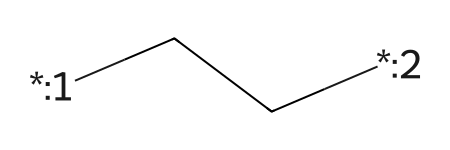

propylene


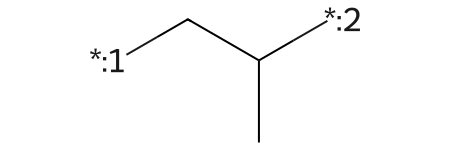

vinyl-cholride


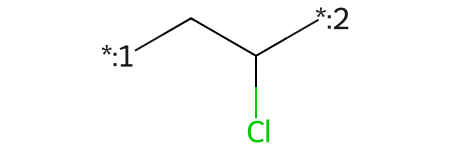

styrene


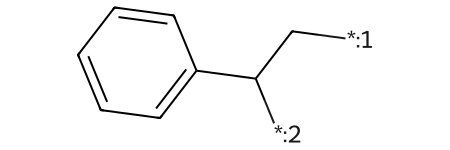

methacrylate


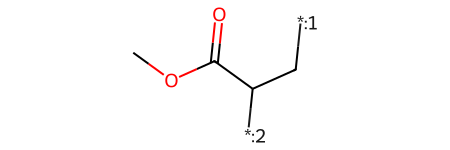

methyl-methacrylate


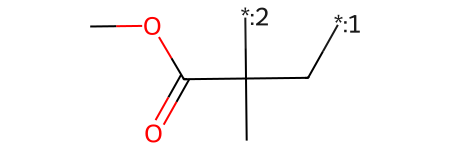

terephthalate


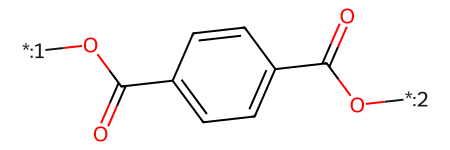

ethylene-terephthalate


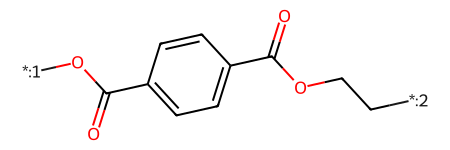

In [2]:
# build and visualize monomer library
SMILES = {
    'ethylene' : '[*:1]-CC-[*:2]',
    'propylene' : '[*:1]-CC([*:2])C',
    'vinyl-cholride' : '[*:1]-CC([*:2])Cl',
    'styrene' : '[*:1]-CC([*:2])c1ccccc1',
    'methacrylate' : '[*:1]-CC([*:2])C(=O)OC',
    'methyl-methacrylate' : '[*:1]-CC(C)([*:2])C(=O)OC',
    'terephthalate' : '[*:1]-OC(=O)c1ccc(C(=O)O[*:2])cc1',
    'ethylene-terephthalate' : '[*:1]-OC(=O)c1ccc(C(=O)OCC[*:2])cc1'
}

for name, smiles in SMILES.items():
    print(name)
    display(Chem.MolFromSmiles(smiles))

# Second level API

This intermediate API is meant to (1) give users more control over generating polymers while not forcing them to dig into the internals of MuPT and (2) to offer convinent and easy-to-use mathematical models for the structure of polymers, including polydispersity, tacticity, and copolymer sequence.

The API is built around a central `TopologyGenerator` class, which constructs descriptive graphs of polymer systems.

# 1. Linear polymers

## Atactic polystyrene with realistic polydispersity

Let's start by generating a simple, atactic styrene oligomer capped with hydrogens.

<Axes: >

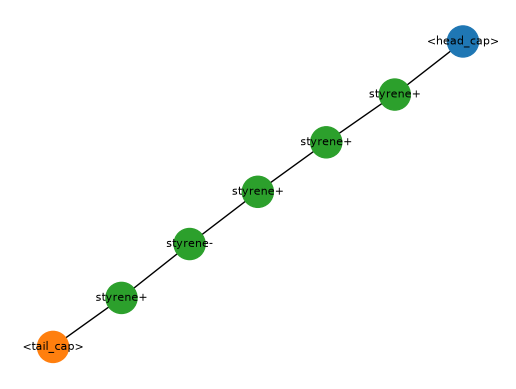

In [3]:
from mupt.polymers.generators import LinearPolymerGenerator
from mupt.polymers.models import atactic, SequenceHomopolymer, SizeSchulzZimm
from mupt.polymers.utils.visualize import draw_topology

# create the generator
aPS_gen = LinearPolymerGenerator(

    # lexicon
    units={
        'styrene' : SMILES['styrene'],
    },

    # size in unit length of polymers
    size=SizeSchulzZimm(
        DPn = 6,
        PDI = 1.2,
    ),

    # stereo-sequece (e.g. tacticity)
    tacticity=atactic(),

    # sequence of units
    sequence=SequenceHomopolymer('styrene'),

    # hydrogen caps
    end_groups='[H]*'
)

# make rng and draw descriptive graph
rng = np.random.default_rng(433562)

draw_topology(
    aPS_gen.generate_topology(rng)
)

In [4]:
aPS_gen.faces

mappingproxy({'styrene': {'head': (1,), 'tail': (2,)},
              '<head_cap>': {'cap': ('Conn',)},
              '<tail_cap>': {'cap': ('Conn',)}})

## To methods of making poly(ethylene terephthlate) (PET)
One is using the full repeat, the other is using an alternating sequence.

<Axes: >

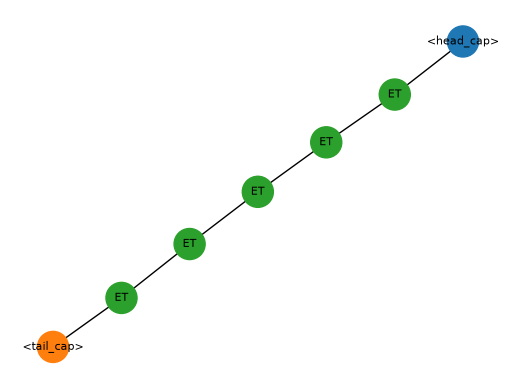

In [4]:
from mupt.polymers import SizeFlory

PET_gen_1 = LinearPolymerGenerator(
    units={
        'ET' : SMILES['ethylene-terephthalate']
    },
    # size model for step-growth
    size=SizeFlory(
        DPn=6,
    ),
    tacticity=None,
    sequence=SequenceHomopolymer('ET'),
    end_groups='[H]*'
)

# make rng and draw descriptive graph
rng = np.random.default_rng(35)

draw_topology(
    PET_gen_1.generate_topology(rng)
)

<Axes: >

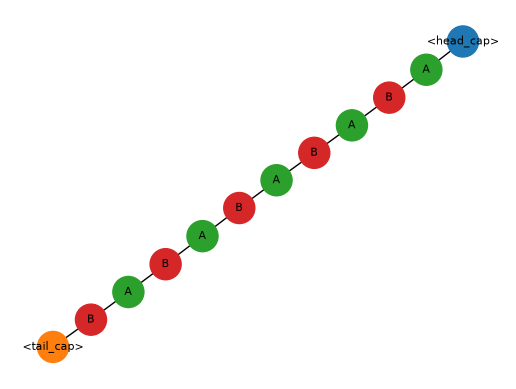

In [5]:
# we can make PET by also using the actual monomers with a repeating sequence
from mupt.polymers import SizeMonodisperse, SequenceAlternating

PET_gen_2 = LinearPolymerGenerator(
    units={
        'A' : SMILES['terephthalate'],
        'B' : SMILES['ethylene'],
    },
    # here we will create a monodisperse sampler
    size=SizeMonodisperse(10),
    sequence=SequenceAlternating(('A', 'B')),
    end_groups='[H]*'
)

# make rng and draw descriptive graph
rng = np.random.default_rng(35)

draw_topology(
    PET_gen_2.generate_topology(rng)
)

## Copolymers with reactivity ratios

What about a more complex copolymer of methylmethacrylate and styrene which have reactivity ratios: $r_{sty}=0.58$, $r_{mma}=0.55$ ([source](https://doi.org/10.1002/pol.1967.150050611)).

<Axes: >

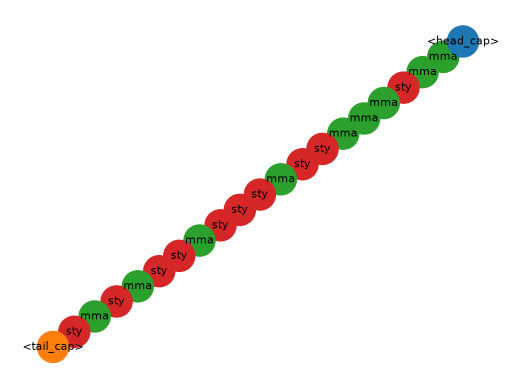

In [6]:
from mupt.polymers import SequenceMayoLewis, TacticityBernoullian

# establish lexicon
lexicon = {
    'sty' : SMILES['styrene'],
    'mma' : SMILES['methyl-methacrylate']
}


# complex sequence model that takes reactivity into account
sequence_model = SequenceMayoLewis(
    feed={
        'sty' : 1.0,
        'mma' : 1.0,
    },
    reactivity={
        ('sty', 'mma') : 0.58,
        ('mma', 'sty') : 0.55,
    }
)

# complex chain end controlled tacticity
# we will model this as ~80% syndiotactic
tacticity_model = TacticityBernoullian(
    p_m=0.2,
)

co_PS_PMMA_gen = LinearPolymerGenerator(
    units=lexicon,
    size=SizeSchulzZimm(
        DPn=12,
        PDI=1.3,
    ),
    sequence=sequence_model,
    end_groups='[H]*'
)

# make rng and draw descriptive graph
rng = np.random.default_rng(134)

draw_topology(
    co_PS_PMMA_gen.generate_topology(rng)
)

## Block copolymers

Block copolymers have two general synthetic pathways: (1) very high self-reactivity ratios in polymerize mix or (2) sequential polymerization, which is more common for well defined blocks.

The accurate modeling of size distributions for a sequentially polymerized polymer requires sampling of both size distributions. These types of block copolymers are the simplests "composite" generator that take in multiple simple generators.

Let's make a tri-block PS-PMMA-PS copolymer with tacticity control on only the styrene.

coarse graph


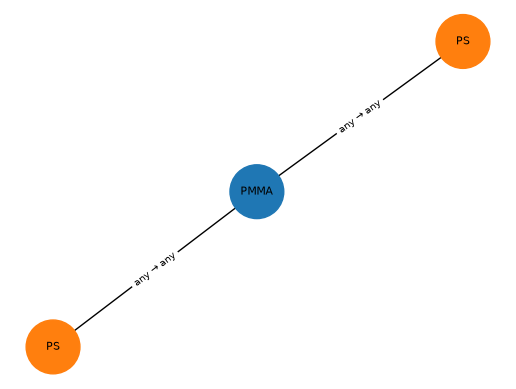

full graph


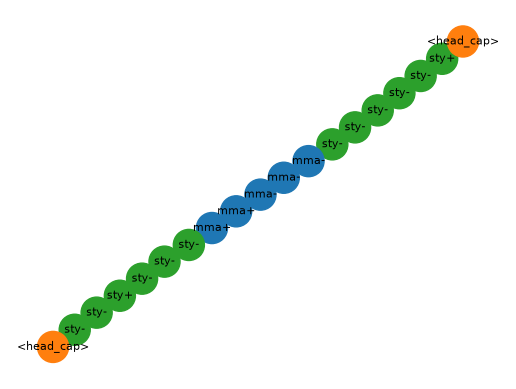

In [13]:
from mupt.polymers import BlockCopolymerGenerator, TacticityEnantiomorphicSite, CompatibleSites
from mupt.polymers.utils.visualize import draw_component_graph

PS_block_gen = LinearPolymerGenerator(
    units={
        'sty' : SMILES['styrene']
    },
    size=SizeMonodisperse(6),
    # importantly leave one end uncapped
    end_groups={
        'head' : '[H]*'
    },
    tacticity=TacticityEnantiomorphicSite(
        sigma=0.9,
        p_flip=0.0,
    )
)

PMMA_block_gen = LinearPolymerGenerator(
    units={
        'mma' : SMILES['methyl-methacrylate']
    },
    size=SizeMonodisperse(5),
    tacticity=atactic(),
    # importantly leave both ends uncapped
    end_groups=None,
)

block_copoly_gen = BlockCopolymerGenerator(
    # every composite generator has a "component" lexicon
    components = {
        'PS' : PS_block_gen,
        'PMMA' : PMMA_block_gen,
    },
    blocks=('PS', 'PMMA', 'PS'),
    # compatibilty tells the generator how to connect each block
    compatibility=CompatibleSites(
        ( ('PS', 'tail'), ('PMMA', 'head') ),
        ( ('PMMA', 'tail'), ('PS', 'tail') ),
    )
)

# make rng and draw descriptive graphs at both resolutions
rng = np.random.default_rng(45462)

print('coarse graph')
draw_component_graph(
    block_copoly_gen.component_graph(rng)
)

plt.show()


print('full graph')
draw_topology(
    block_copoly_gen.generate_topology(rng)
)
plt.show()

## Star polymers

coarse graph


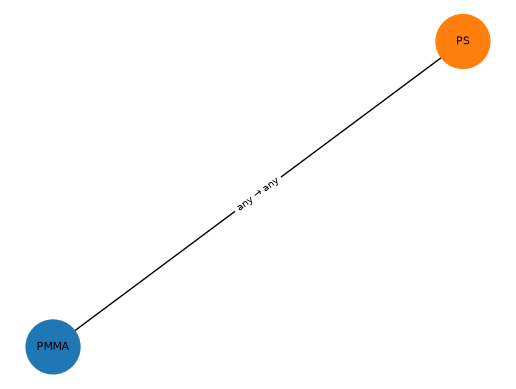

full graph


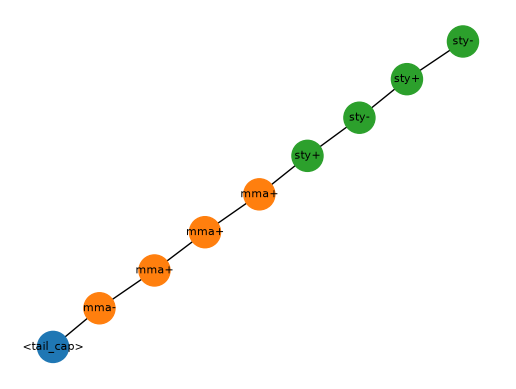

In [37]:
PS_block_gen = LinearPolymerGenerator(
    units={
        'sty' : SMILES['styrene']
    },
    size=SizeMonodisperse(4),
    tacticity=atactic(),
    end_groups=None,
)

PMMA_block_gen = LinearPolymerGenerator(
    units={
        'mma' : SMILES['methyl-methacrylate']
    },
    size=SizeMonodisperse(4),
    tacticity=atactic(),
    # importantly leave both ends uncapped
    end_groups={
        'tail' : '[H]*'
    },
)

arm_gen = BlockCopolymerGenerator(
    components={
        'PS' : PS_block_gen,
        'PMMA' : PMMA_block_gen,
    },
    blocks=( 'PS', 'PMMA' ),
    compatibility=CompatibleSites(
        ( ('PS', 'tail'), ('PMMA', 'head') ),
    )
)

# make rng and draw descriptive graphs at both resolutions
rng = np.random.default_rng(45462)

print('coarse graph')
draw_component_graph(
    arm_gen.component_graph(rng)
)

plt.show()

print('full graph')
draw_topology(
    arm_gen.generate_topology(rng)
)
plt.show()

In [38]:
arm_gen.faces

mappingproxy({('PS', 'sty'): {'head': (1,), 'tail': (2,)},
              ('PMMA', 'mma'): {'head': (1,), 'tail': (2,)},
              ('PMMA', '<tail_cap>'): {'cap': ('Conn',)}})

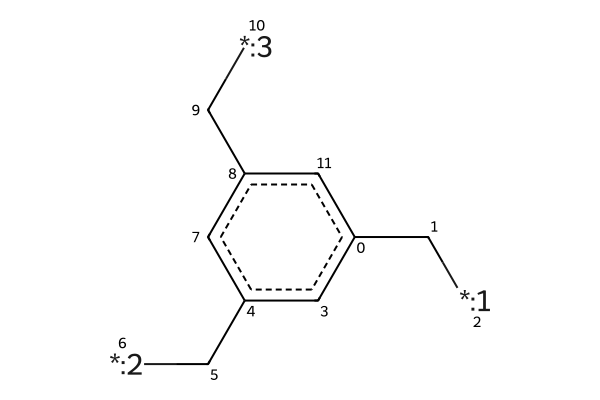

In [39]:
hub_smiles = 'c1(C[*:1])cc(C[*:2])cc(C[*:3])c1'
display(Chem.MolFromSmiles(hub_smiles))

coarse graph


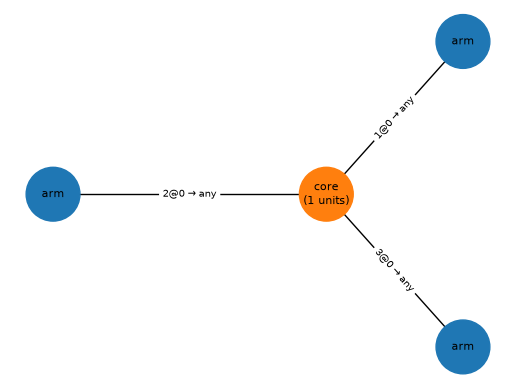

full graph


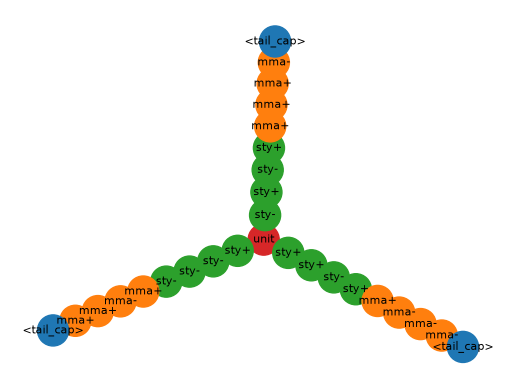

In [40]:
from mupt.polymers import StarPolymerGenerator, UnitGenerator

star_gen = StarPolymerGenerator(
    components={
        'arm' : arm_gen,
        'core' : UnitGenerator(hub_smiles)
    },
    core='core',
    arms={
        (1, 2, 3) : 'arm'
    },
    #compatibility=CompatibleSites(
    #    ( ('core', 'unit', 1), ( 'arm', 'PS', 'sty', 'tail' ) ),
    #)
)

# make rng and draw descriptive graphs at both resolutions
rng = np.random.default_rng(45462)

print('coarse graph')
draw_component_graph(
    star_gen.component_graph(rng)
)

plt.show()

print('full graph')
draw_topology(
    star_gen.generate_topology(rng)
)
plt.show()

In [25]:
gen = UnitGenerator(hub_smiles)
gen.faces

mappingproxy({'unit': {1: (1,), 2: (2,), 3: (3,)}})